In [1]:
pip install pandas numpy matplotlib scikit-learn torch yfinance


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import yfinance as yf
import pandas as pd

df = yf.download("TCS.NS", start="2019-01-01", end="2026-10-31")
df = df[["Open", "High", "Low", "Close", "Volume"]]
df.to_csv("stock.csv")
print(df.shape)
df.head()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

(1935, 5)



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


Price,Open,High,Low,Close,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2019-01-01,1538.759888,1550.122039,1529.832483,1544.278687,1094883
2019-01-02,1546.064143,1569.965200,1542.006232,1560.916138,2100463
2019-01-03,1557.426503,1578.487025,1536.406501,1541.965820,2611668
2019-01-04,1542.006165,1542.980024,1494.122816,1523.218018,4280862
2019-01-07,1535.351370,1549.148268,1526.586242,1540.302002,1856423


In [5]:
import warnings
warnings.filterwarnings("ignore")

df.columns = df.columns.get_level_values(0)
df.index = pd.to_datetime(df.index)
df.head()

Price,Open,High,Low,Close,Volume
Date,,,,,
2019-01-01,1538.759888,1550.122039,1529.832483,1544.278687,1094883
2019-01-02,1546.064143,1569.965200,1542.006232,1560.916138,2100463
2019-01-03,1557.426503,1578.487025,1536.406501,1541.965820,2611668
2019-01-04,1542.006165,1542.980024,1494.122816,1523.218018,4280862
2019-01-07,1535.351370,1549.148268,1526.586242,1540.302002,1856423


In [7]:
print(df.info())
print("Missing values:\n", df.isnull().sum())
print(df.describe())

<class 'pandas.DataFrame'>
DatetimeIndex: 1935 entries, 2019-01-01 to 2026-10-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1935 non-null   float64
 1   High    1935 non-null   float64
 2   Low     1935 non-null   float64
 3   Close   1935 non-null   float64
 4   Volume  1935 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 90.7 KB
None
Missing values:
 Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Price         Open         High          Low        Close        Volume
count  1935.000000  1935.000000  1935.000000  1935.000000  1.935000e+03
mean   2753.979499  2780.057005  2726.393747  2752.353219  2.901743e+06
std     683.967205   687.633968   680.681205   684.002664  1.815127e+06
min    1323.184144  1429.865179  1268.402449  1388.210815  0.000000e+00
25%    2207.033380  2242.783152  2181.801436  2204.270874  1.779626e+06
50%    2881.549556  2903.888147  2857.393088

In [9]:
df = df[~df.index.duplicated()]
df = df.sort_index()
df = df.ffill().dropna()
print(df.shape)

(1935, 5)


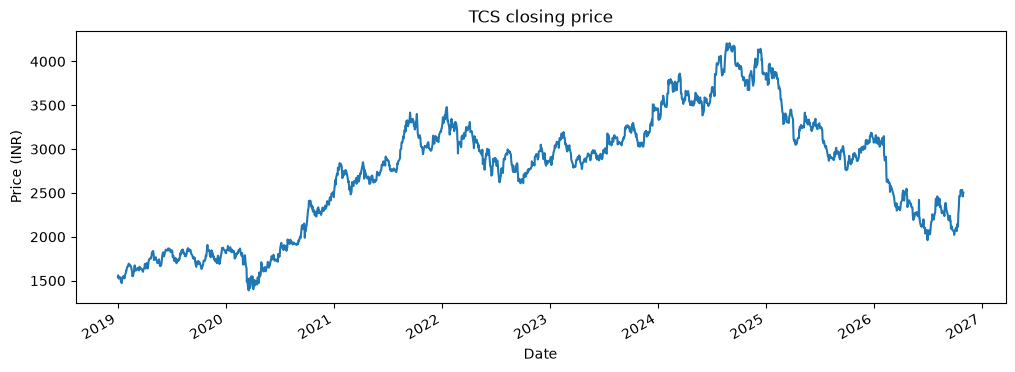

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
df["Close"].plot(title="TCS closing price")
plt.ylabel("Price (INR)")
plt.show()

In [12]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

WINDOW = 60
features = ["Open", "High", "Low", "Close", "Volume"]
data = df[features].values
split = int(len(data) * 0.8)

# 1. scale (fit on training days only)
scaler = MinMaxScaler()
scaler.fit(data[:split])
scaled = scaler.transform(data)

# 2. build windows: 60 days -> next day's Close (column 3)
X, y = [], []
for i in range(WINDOW, len(scaled)):
    X.append(scaled[i - WINDOW:i])
    y.append(scaled[i, 3])
X, y = np.array(X), np.array(y)

# 3. time-based split
n_train = split - WINDOW
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

X_train: (1488, 60, 5) y_train: (1488,)
X_test:  (387, 60, 5) y_test:  (387,)


In [13]:
import torch, torch.nn as nn
from sklearn.metrics import mean_squared_error, mean_absolute_error

torch.manual_seed(42)
np.random.seed(42)

c_min, c_range = scaler.data_min_[3], scaler.data_range_[3]
to_inr = lambda v: v * c_range + c_min

results = {}
def score(name, pred_scaled):
    actual = to_inr(y_test)
    pred = to_inr(np.array(pred_scaled).flatten())
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    results[name] = (rmse, mae, pred)
    print(f"{name}: RMSE = {rmse:.2f} INR, MAE = {mae:.2f} INR")

# Baseline: tomorrow's close = today's close (last day in each window)
score("Naive baseline", X_test[:, -1, 3])

Naive baseline: RMSE = 43.15 INR, MAE = 30.72 INR


In [14]:
Xtr = torch.tensor(X_train, dtype=torch.float32).reshape(len(X_train), -1)
ytr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
Xte = torch.tensor(X_test, dtype=torch.float32).reshape(len(X_test), -1)

# last 10% of training data used for validation (time order kept)
v = int(len(Xtr) * 0.9)
Xt, yt, Xv, yv = Xtr[:v], ytr[:v], Xtr[v:], ytr[v:]

ann = nn.Sequential(
    nn.Linear(300, 128), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 1)
)
opt = torch.optim.Adam(ann.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

train_loss, val_loss = [], []
best, patience, wait = 1e9, 10, 0
for epoch in range(100):
    ann.train()
    for i in range(0, len(Xt), 32):
        opt.zero_grad()
        loss = loss_fn(ann(Xt[i:i+32]), yt[i:i+32])
        loss.backward()
        opt.step()
    ann.eval()
    with torch.no_grad():
        tl = loss_fn(ann(Xt), yt).item()
        vl = loss_fn(ann(Xv), yv).item()
    train_loss.append(tl); val_loss.append(vl)
    if vl < best:
        best, wait = vl, 0
        torch.save(ann.state_dict(), "ann_best.pt")
    else:
        wait += 1
        if wait >= patience:
            print("Early stop at epoch", epoch); break

ann.load_state_dict(torch.load("ann_best.pt"))
ann.eval()
with torch.no_grad():
    score("ANN", ann(Xte).numpy())

Early stop at epoch 24
ANN: RMSE = 132.62 INR, MAE = 109.32 INR


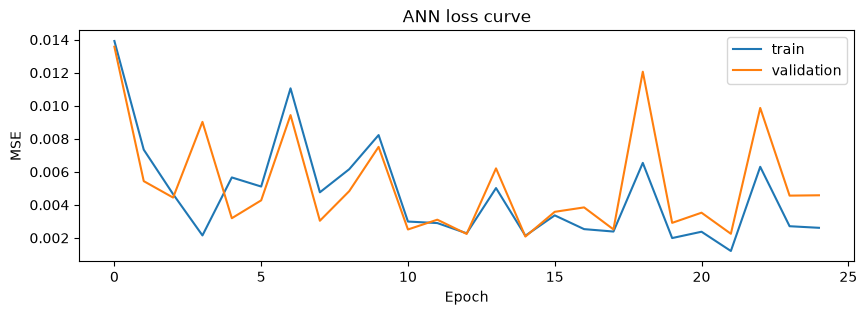

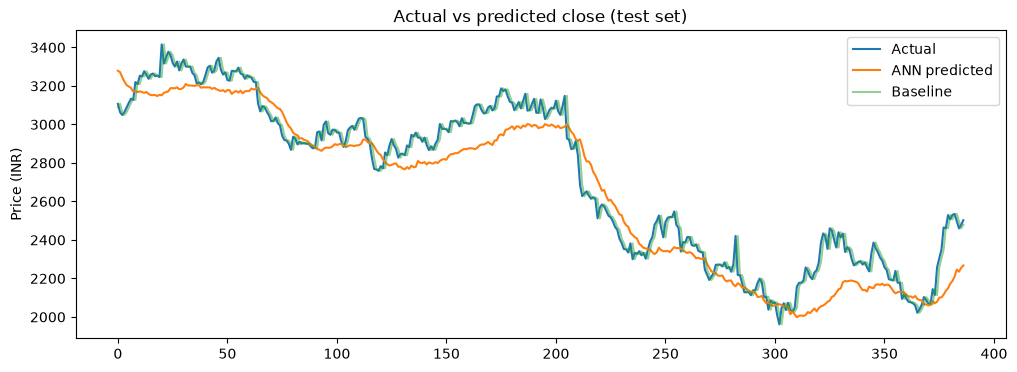

In [15]:
plt.figure(figsize=(10, 3))
plt.plot(train_loss, label="train"); plt.plot(val_loss, label="validation")
plt.title("ANN loss curve"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(to_inr(y_test), label="Actual")
plt.plot(results["ANN"][2], label="ANN predicted")
plt.plot(results["Naive baseline"][2], label="Baseline", alpha=0.5)
plt.title("Actual vs predicted close (test set)"); plt.ylabel("Price (INR)"); plt.legend(); plt.show()

In [16]:
Xtr_l = torch.tensor(X_train, dtype=torch.float32)   # shape (samples, 60, 5)
Xte_l = torch.tensor(X_test, dtype=torch.float32)
Xt_l, Xv_l = Xtr_l[:v], Xtr_l[v:]

class LSTMNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=5, hidden_size=64, num_layers=2,
                            batch_first=True, dropout=0.2)
        self.fc = nn.Linear(64, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])   # use the last day's output

lstm = LSTMNet()
opt = torch.optim.Adam(lstm.parameters(), lr=0.001)

l_train, l_val = [], []
best, wait = 1e9, 0
for epoch in range(100):
    lstm.train()
    for i in range(0, len(Xt_l), 32):
        opt.zero_grad()
        loss = loss_fn(lstm(Xt_l[i:i+32]), yt[i:i+32])
        loss.backward()
        opt.step()
    lstm.eval()
    with torch.no_grad():
        tl = loss_fn(lstm(Xt_l), yt).item()
        vl = loss_fn(lstm(Xv_l), yv).item()
    l_train.append(tl); l_val.append(vl)
    if vl < best:
        best, wait = vl, 0
        torch.save(lstm.state_dict(), "lstm_best.pt")
    else:
        wait += 1
        if wait >= 10:
            print("Early stop at epoch", epoch); break

lstm.load_state_dict(torch.load("lstm_best.pt"))
lstm.eval()
with torch.no_grad():
    score("LSTM", lstm(Xte_l).numpy())

Early stop at epoch 59
LSTM: RMSE = 66.86 INR, MAE = 51.71 INR


In [17]:
# 1. new target: next-day % change
today_all = to_inr(X[:, -1, 3])
next_all = to_inr(y)
ret = next_all / today_all - 1
r_std = ret[:n_train].std()                      # scale using training data only
yr = torch.tensor(ret / r_std, dtype=torch.float32).unsqueeze(1)
yrt, yrv = yr[:n_train][:v], yr[:n_train][v:]
today_test = today_all[n_train:]

# 2. training helper (same early stopping as before)
def fit(model, Xt_, Xv_, name):
    opt = torch.optim.Adam(model.parameters(), lr=0.001)
    best, wait = 1e9, 0
    for epoch in range(100):
        model.train()
        for i in range(0, len(Xt_), 32):
            opt.zero_grad()
            loss_fn(model(Xt_[i:i+32]), yrt[i:i+32]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(Xv_), yrv).item()
        if vl < best:
            best, wait = vl, 0
            torch.save(model.state_dict(), name + ".pt")
        else:
            wait += 1
            if wait >= 10:
                break
    model.load_state_dict(torch.load(name + ".pt"))
    model.eval()
    return model

# 3. convert predicted change back to a price and score it
def score_change(name, model, X_in):
    with torch.no_grad():
        r = model(X_in).numpy().flatten() * r_std
    pred = today_test * (1 + r)
    actual = to_inr(y_test)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    results[name] = (rmse, mae, pred)
    print(f"{name}: RMSE = {rmse:.2f} INR, MAE = {mae:.2f} INR")

# 4. train both models on the new target
torch.manual_seed(42)
ann2 = nn.Sequential(nn.Linear(300, 128), nn.ReLU(), nn.Dropout(0.2),
                     nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
                     nn.Linear(64, 1))
ann2 = fit(ann2, Xt, Xv, "ann_change")
score_change("ANN (change)", ann2, Xte)

lstm2 = fit(LSTMNet(), Xt_l, Xv_l, "lstm_change")
score_change("LSTM (change)", lstm2, Xte_l)

# 5. final table
for name, (rmse, mae, _) in results.items():
    print(f"{name:16s} RMSE {rmse:8.2f}   MAE {mae:8.2f}")

ANN (change): RMSE = 43.14 INR, MAE = 30.80 INR
LSTM (change): RMSE = 43.24 INR, MAE = 30.97 INR
Naive baseline   RMSE    43.15   MAE    30.72
ANN              RMSE   132.62   MAE   109.32
LSTM             RMSE    66.86   MAE    51.71
ANN (change)     RMSE    43.14   MAE    30.80
LSTM (change)    RMSE    43.24   MAE    30.97


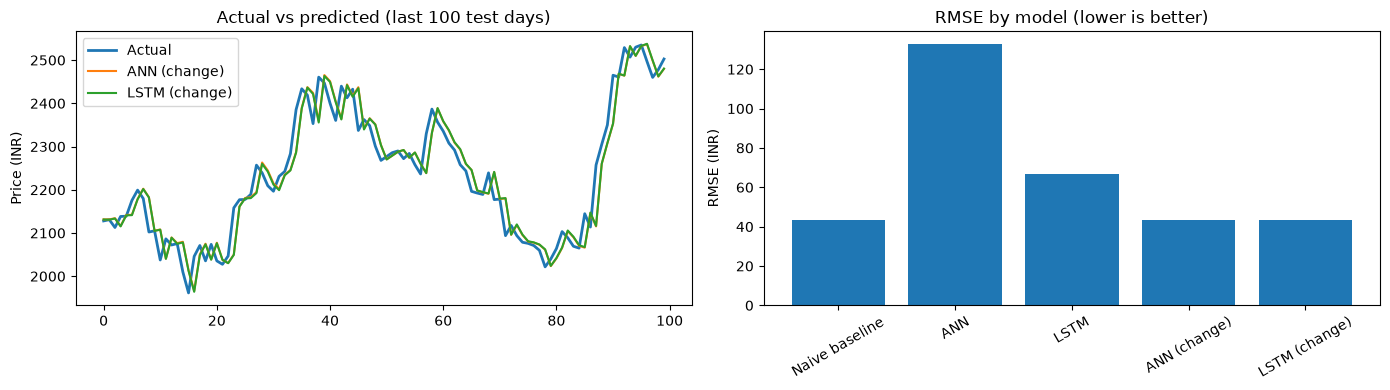

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Left: last 100 test days, zoomed so the lines are readable
actual = to_inr(y_test)
ax[0].plot(actual[-100:], label="Actual", linewidth=2)
ax[0].plot(results["ANN (change)"][2][-100:], label="ANN (change)")
ax[0].plot(results["LSTM (change)"][2][-100:], label="LSTM (change)")
ax[0].set_title("Actual vs predicted (last 100 test days)")
ax[0].set_ylabel("Price (INR)"); ax[0].legend()

# Right: error comparison
names = list(results.keys())
ax[1].bar(names, [results[n][0] for n in names])
ax[1].set_title("RMSE by model (lower is better)")
ax[1].set_ylabel("RMSE (INR)")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [19]:
import joblib

def predict_next(model, recent_df):
    w = scaler.transform(recent_df[features].values[-60:])
    x = torch.tensor(w[None], dtype=torch.float32)
    with torch.no_grad():
        r = model(x).numpy().flatten()[0] * r_std
    return recent_df["Close"].iloc[-1] * (1 + r)

print("Last close:", round(df["Close"].iloc[-1], 2))
print("Predicted next close:", round(predict_next(lstm2, df), 2))

joblib.dump(scaler, "scaler.pkl")
pd.DataFrame({k: v[:2] for k, v in results.items()}, index=["RMSE", "MAE"]).T.to_csv("results.csv")

Last close: 2502.6
Predicted next close: 2504.93
